## Figure 3

Parameter dependences of <$S_z$> and <$L_z$>

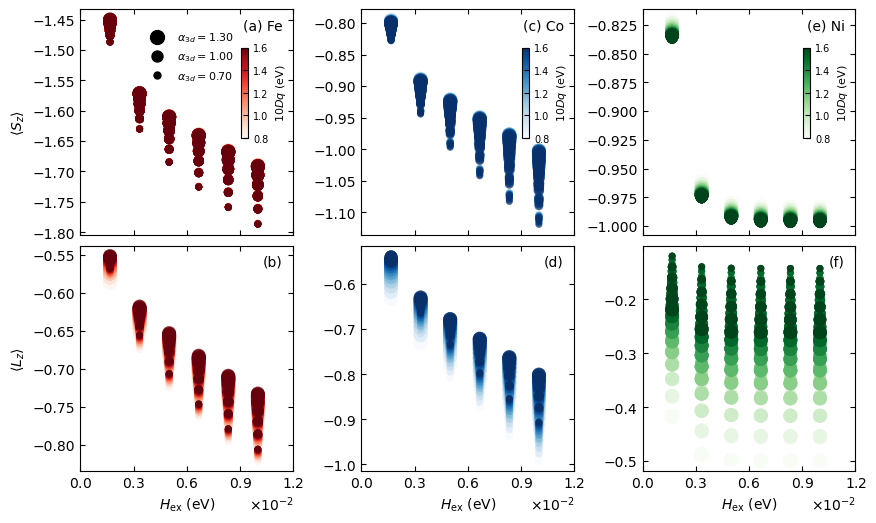


PNG saved: figures/Figure3_Sz_Lz_multi.png
PDF saved: figures/Figure3_Sz_Lz_multi.pdf


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator
from matplotlib.ticker import ScalarFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


# ============================================================
# Configuration
# ============================================================

figure_name = "Figure3"

output_dpi = 300

zero_tolerance = 1.0e-6


# ============================================================
# Repository root
# ============================================================

def find_repository_root():
    current = Path.cwd().resolve()

    for candidate in [
        current,
        *current.parents,
    ]:
        if (
            (candidate / "src").is_dir()
            and (candidate / "configs").is_dir()
        ):
            return candidate

    raise FileNotFoundError(
        "Repository root was not found"
    )


repository_root = (
    find_repository_root()
)

output_directory = (
    repository_root
    / "figures"
)

output_directory.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# CSV files
# ============================================================

files = {
    "Fe": (
        repository_root
        / "quanty"
        / "runs"
        / "quanty_results_Fe_d6.csv"
    ),

    "Co": (
        repository_root
        / "quanty"
        / "runs"
        / "quanty_results_Co_d7.csv"
    ),

    "Ni": (
        repository_root
        / "quanty"
        / "runs"
        / "quanty_results_Ni_d8.csv"
    ),
}

elements = [
    "Fe",
    "Co",
    "Ni",
]


# ============================================================
# Column detection
# ============================================================

def find_column(
    dataframe,
    candidates,
):
    """
    Find a column name from a list of possible aliases.
    """

    for candidate in candidates:
        if candidate in dataframe.columns:
            return candidate

    raise KeyError(
        "None of these columns were found:\n"
        f"{candidates}"
    )


parameter_aliases = {
    "ten_dq": [
        "TEN_DQ",
        "10Dq",
        "ten_dq",
    ],

    "soc_3d": [
        "SOC_3d",
        "SOC3d",
        "soc_3d",
    ],

    "hex": [
        "H_ex",
        "Hex",
        "hex",
    ],

    "sz": [
        "Sz",
        "sz",
    ],

    "lz": [
        "Lz",
        "lz",
    ],
}


# ============================================================
# Colormaps
# ============================================================

cmap_dict = {
    "Fe": plt.cm.Reds,
    "Co": plt.cm.Blues,
    "Ni": plt.cm.Greens,
}


# ============================================================
# Load data
# ============================================================

data = {}

all_ten_dq = []
all_soc3d = []

for element in elements:

    csv_file = files[
        element
    ]

    if not csv_file.is_file():
        raise FileNotFoundError(
            csv_file
        )

    dataframe = pd.read_csv(
        csv_file
    )

    ten_dq_column = find_column(
        dataframe,
        parameter_aliases[
            "ten_dq"
        ],
    )

    soc3d_column = find_column(
        dataframe,
        parameter_aliases[
            "soc_3d"
        ],
    )

    hex_column = find_column(
        dataframe,
        parameter_aliases[
            "hex"
        ],
    )

    sz_column = find_column(
        dataframe,
        parameter_aliases[
            "sz"
        ],
    )

    lz_column = find_column(
        dataframe,
        parameter_aliases[
            "lz"
        ],
    )

    dataframe = dataframe[
        ~(
            (
                dataframe[
                    sz_column
                ].abs()
                < zero_tolerance
            )
            &
            (
                dataframe[
                    lz_column
                ].abs()
                < zero_tolerance
            )
        )
    ].copy()

    dataframe["_ten_dq"] = (
        dataframe[
            ten_dq_column
        ]
    )

    dataframe["_soc3d"] = (
        dataframe[
            soc3d_column
        ]
    )

    dataframe["_hex"] = (
        dataframe[
            hex_column
        ]
    )

    dataframe["_sz"] = (
        dataframe[
            sz_column
        ]
    )

    dataframe["_lz"] = (
        dataframe[
            lz_column
        ]
    )

    data[
        element
    ] = dataframe

    all_ten_dq.extend(
        dataframe[
            "_ten_dq"
        ]
    )

    all_soc3d.extend(
        dataframe[
            "_soc3d"
        ]
    )


all_ten_dq = np.asarray(
    all_ten_dq,
    dtype=float,
)

all_soc3d = np.asarray(
    all_soc3d,
    dtype=float,
)

if len(all_ten_dq) == 0:
    raise RuntimeError(
        "No points available"
    )

norm = Normalize(
    vmin=float(
        np.min(
            all_ten_dq
        )
    ),
    vmax=float(
        np.max(
            all_ten_dq
        )
    ),
)


# ============================================================
# Marker-size scaling
# ============================================================

size_min = 25
size_max = 100


# ============================================================
# Figure
# ============================================================

figure, axes = plt.subplots(
    2,
    3,
    figsize=(10, 6),
    sharex="col",
)

plt.subplots_adjust(
    hspace=0.05,
    wspace=0.32,
)

panel_labels = {
    (0, 0): "(a)",
    (1, 0): "(b)",
    (0, 1): "(c)",
    (1, 1): "(d)",
    (0, 2): "(e)",
    (1, 2): "(f)",
}


# ============================================================
# Plot
# ============================================================

for column, element in enumerate(
    elements
):
    dataframe = data[
        element
    ]

    hex_values = dataframe[
        "_hex"
    ].to_numpy(
        dtype=float
    )

    sz_values = dataframe[
        "_sz"
    ].to_numpy(
        dtype=float
    )

    lz_values = dataframe[
        "_lz"
    ].to_numpy(
        dtype=float
    )

    ten_dq_values = dataframe[
        "_ten_dq"
    ].to_numpy(
        dtype=float
    )

    soc3d_values = dataframe[
        "_soc3d"
    ].to_numpy(
        dtype=float
    )

    soc_norm = (
        soc3d_values
        - np.min(
            all_soc3d
        )
    ) / (
        np.max(
            all_soc3d
        )
        - np.min(
            all_soc3d
        )
    )

    marker_sizes = (
        size_min
        + soc_norm
        * (
            size_max
            - size_min
        )
    )

    cmap = cmap_dict[
        element
    ]

    # ------------------------------------------
    # Sz
    # ------------------------------------------

    axis = axes[
        0,
        column,
    ]

    axis.scatter(
        hex_values,
        sz_values,
        c=ten_dq_values,
        cmap=cmap,
        norm=norm,
        s=marker_sizes,
        alpha=0.35,
        edgecolors="none",
    )

    axis.text(
        0.95,
        0.96,
        (
            panel_labels[
                (
                    0,
                    column,
                )
            ]
            + f" {element}"
        ),
        transform=axis.transAxes,
        ha="right",
        va="top",
    )

    axis.tick_params(
        labelbottom=False,
        direction="in",
        top=True,
        right=True,
    )

    # ------------------------------------------
    # Lz
    # ------------------------------------------

    axis = axes[
        1,
        column,
    ]

    axis.scatter(
        hex_values,
        lz_values,
        c=ten_dq_values,
        cmap=cmap,
        norm=norm,
        s=marker_sizes,
        alpha=0.35,
        edgecolors="none",
    )

    axis.text(
        0.95,
        0.96,
        panel_labels[
            (
                1,
                column,
            )
        ],
        transform=axis.transAxes,
        ha="right",
        va="top",
    )

    axis.tick_params(
        direction="in",
        top=True,
        right=True,
    )


# ============================================================
# Labels
# ============================================================

axes[
    0,
    0,
].set_ylabel(
    r"$\langle S_z \rangle$"
)

axes[
    1,
    0,
].set_ylabel(
    r"$\langle L_z \rangle$"
)

for column in range(3):
    axes[
        1,
        column,
    ].set_xlabel(
        r"$H_{\mathrm{ex}}$ (eV)"
    )


# ============================================================
# Axis formatting
# ============================================================

for axis in axes.flatten():

    formatter = ScalarFormatter(
        useMathText=True
    )

    formatter.set_powerlimits(
        (-2, -2)
    )

    axis.xaxis.set_major_formatter(
        formatter
    )

    axis.xaxis.set_major_locator(
        MaxNLocator(
            4
        )
    )

    axis.set_xlim(
        0,
        0.012,
    )


# ============================================================
# Color bars
# ============================================================

for column, element in enumerate(
    elements
):
    axis = axes[
        0,
        column,
    ]

    scalar_mappable = ScalarMappable(
        norm=norm,
        cmap=cmap_dict[
            element
        ],
    )

    scalar_mappable.set_array(
        []
    )

    color_axis = inset_axes(
        axis,
        width="3.5%",
        height="40%",
        loc="upper right",
        bbox_to_anchor=(
            -0.18,
            -0.14,
            1,
            1,
        ),
        bbox_transform=axis.transAxes,
        borderpad=0.5,
    )

    colorbar = figure.colorbar(
        scalar_mappable,
        cax=color_axis,
    )

    colorbar.ax.tick_params(
        labelsize=7,
        direction="in",
    )

    colorbar.set_label(
        r"$10Dq$ (eV)",
        fontsize=8,
    )


# ============================================================
# Marker size legend
# ============================================================

soc_levels = np.linspace(
    np.min(
        all_soc3d
    ),
    np.max(
        all_soc3d
    ),
    3,
)

size_levels = (
    size_min
    + (
        soc_levels
        - np.min(
            all_soc3d
        )
    )
    / (
        np.max(
            all_soc3d
        )
        - np.min(
            all_soc3d
        )
    )
    * (
        size_max
        - size_min
    )
)

legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="None",
        color="black",
        markersize=np.sqrt(
            size
        ),
        label=(
            rf"$\alpha_{{3d}}="
            f"{soc:.2f}$"
        ),
    )
    for soc, size in zip(
        soc_levels,
        size_levels,
    )
]

axes[
    0,
    0,
].legend(
    handles=legend_handles[
        ::-1
    ],
    loc="upper left",
    bbox_to_anchor=(
        0.26,
        0.95,
    ),
    frameon=False,
    fontsize=8,
)


# ============================================================
# Save
# ============================================================

png_file = (
    output_directory
    / f"{figure_name}_Sz_Lz_multi.png"
)

pdf_file = (
    output_directory
    / f"{figure_name}_Sz_Lz_multi.pdf"
)

plt.savefig(
    png_file,
    dpi=output_dpi,
    bbox_inches="tight",
)

plt.savefig(
    pdf_file,
    bbox_inches="tight",
)

plt.show()

print()
print(
    "PNG saved:",
    png_file.relative_to(
        repository_root
    )
)

print(
    "PDF saved:",
    pdf_file.relative_to(
        repository_root
    )
)